# Telco Customer Churn — Exploratory Data Analysis

**Phase 2 · M.Tech AIML · ML Assignment 2**

This notebook describes the raw dataset (`data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv`, 7,043 customers).
It is descriptive only: no encoder, scaler or model is fitted here, so looking at all rows does not leak
information into the models trained later. Cleaning uses the same stateless `clean_features()` function as
the modelling pipeline in `src/preprocessing.py` (TotalCharges converted to numeric; the 11 blanks, all
`tenure == 0`, set to 0).

Colour convention used in every chart: **blue = stayed (Churn = No)**, **orange = churned (Churn = Yes)**.
Figures are also saved to `src/results/eda/`.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import PercentFormatter
from IPython.display import display

# Locate the project root (the folder containing src/) so imports work from src/notebooks/.
PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "preprocessing.py").exists())
sys.path.insert(0, str(PROJECT_ROOT))
from src.preprocessing import NUMERICAL_FEATURES, clean_features, load_raw_data, split_features_target

FIG_DIR = PROJECT_ROOT / "src" / "results" / "eda"
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Palette: validated categorical slots 1-2 plus neutral chart chrome.
STAYED, CHURNED, NEUTRAL = "#2a78d6", "#eb6834", "#898781"
SURFACE, INK, INK_2, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#e1e0d9", "#c3c2b7"

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
    "font.size": 11, "axes.titlesize": 13, "axes.titleweight": "semibold", "axes.titlepad": 12,
    "text.color": INK, "axes.labelcolor": INK_2, "xtick.color": INK_2, "ytick.color": INK_2,
    "axes.edgecolor": AXIS, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "legend.frameon": False,
})

raw = load_raw_data()
X, y = split_features_target(raw)
df = clean_features(X)
df["Churn"] = raw["Churn"]
df["churned"] = y
OVERALL_RATE = y.mean()
print(f"{len(df):,} customers, overall churn rate {OVERALL_RATE:.2%}")

7,043 customers, overall churn rate 26.54%


## 1. Target class distribution

,customers,share
Churn,,
No,5174,73.46%
Yes,1869,26.54%


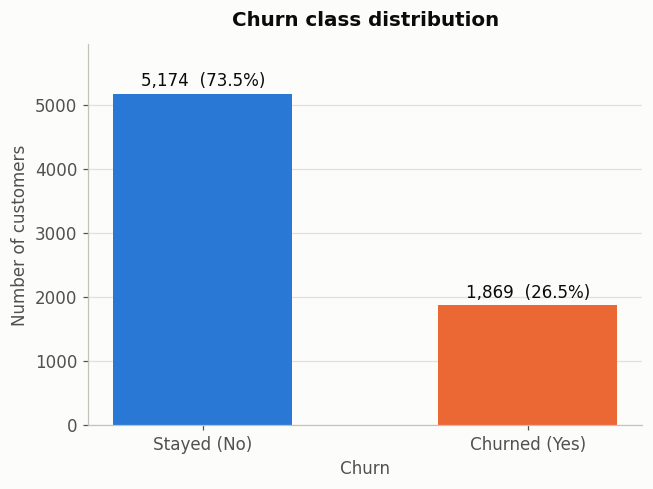

In [2]:
counts = df["Churn"].value_counts().reindex(["No", "Yes"])
shares = counts / counts.sum()
display(pd.DataFrame({"customers": counts, "share": shares.map("{:.2%}".format)}))

fig, ax = plt.subplots(figsize=(6.5, 4.5))
bars = ax.bar(["Stayed (No)", "Churned (Yes)"], counts, color=[STAYED, CHURNED], width=0.55)
for bar, n, s in zip(bars, counts, shares):
    ax.annotate(f"{n:,}  ({s:.1%})", (bar.get_x() + bar.get_width() / 2, n),
                xytext=(0, 5), textcoords="offset points", ha="center", color=INK)
ax.set_title("Churn class distribution")
ax.set_xlabel("Churn")
ax.set_ylabel("Number of customers")
ax.set_ylim(0, counts.max() * 1.15)
ax.grid(axis="x", visible=False)
fig.savefig(FIG_DIR / "01_target_distribution.png")
plt.show()

**Observation.** 5,174 customers stayed (73.46%) and 1,869 churned (26.54%), about 2.8 : 1.
A model that always predicts "No" would already reach 73.5% accuracy, so accuracy alone is misleading.
Later phases should use a stratified split (done) and report precision, recall, F1, AUC and MCC alongside accuracy.

## 2–4. Churn rate by Contract, InternetService and PaymentMethod

In [3]:
def churn_rate_table(column):
    table = (df.groupby(column)["churned"].agg(customers="size", churned="sum", churn_rate="mean")
               .sort_values("churn_rate", ascending=False))
    return table


def plot_churn_rate(column, title, filename):
    table = churn_rate_table(column)
    display(table.style.format({"churn_rate": "{:.1%}", "customers": "{:,}", "churned": "{:,}"}))

    fig, ax = plt.subplots(figsize=(8.5, 0.75 * len(table) + 1.6))
    labels = table.index[::-1]
    rates = table["churn_rate"][::-1]
    ax.barh(labels, rates, color=CHURNED, height=0.55)
    for label, rate, n in zip(labels, rates, table["customers"][::-1]):
        ax.annotate(f"{rate:.1%}  (n={n:,})", (rate, label), xytext=(6, 0),
                    textcoords="offset points", va="center", color=INK_2, zorder=3,
                    bbox=dict(facecolor=SURFACE, edgecolor="none", pad=1.5))
    ax.axvline(OVERALL_RATE, color=INK_2, linestyle="--", linewidth=1.2, zorder=2)
    ax.annotate(f"Overall churn rate {OVERALL_RATE:.1%}", (OVERALL_RATE, 0.0), xycoords=("data", "axes fraction"),
                xytext=(5, 5), textcoords="offset points", color=INK_2, fontsize=10)
    ax.set_title(title)
    ax.set_xlabel("Churn rate (share of customers in the group who left)")
    ax.set_ylabel(column)
    ax.xaxis.set_major_formatter(PercentFormatter(1.0))
    ax.set_xlim(0, max(table["churn_rate"].max() * 1.35, OVERALL_RATE * 1.2))
    ax.grid(axis="y", visible=False)
    fig.savefig(FIG_DIR / filename)
    plt.show()

### 2. Churn by Contract

,customers,churned,churn_rate
Contract,,,
Month-to-month,"3,875","1,655",42.7%
One year,"1,473",166,11.3%
Two year,"1,695",48,2.8%


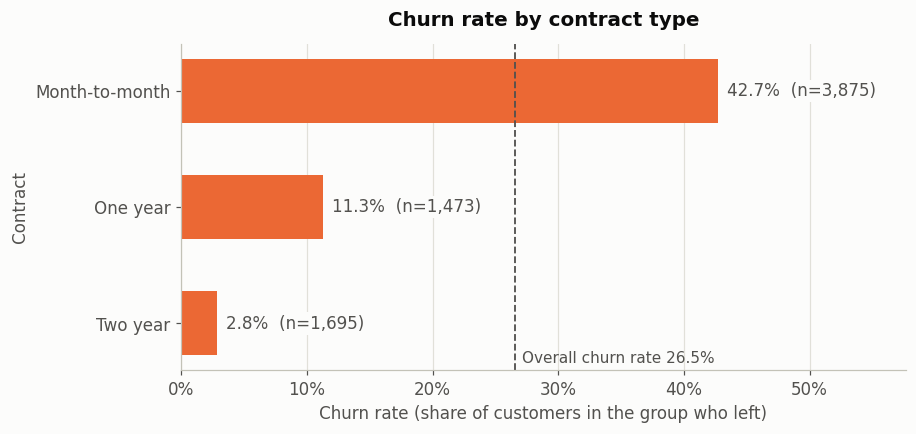

In [4]:
plot_churn_rate("Contract", "Churn rate by contract type", "02_churn_by_contract.png")

**Observation.** Contract length is the strongest single pattern in the data. Month-to-month customers churn at
**42.7%**, versus **11.3%** on one-year and only **2.8%** on two-year contracts. Month-to-month is also the
largest group (3,875 customers, 55%), so it accounts for the large majority of all churners.

### 3. Churn by InternetService

,customers,churned,churn_rate
InternetService,,,
Fiber optic,"3,096","1,297",41.9%
DSL,"2,421",459,19.0%
No,"1,526",113,7.4%


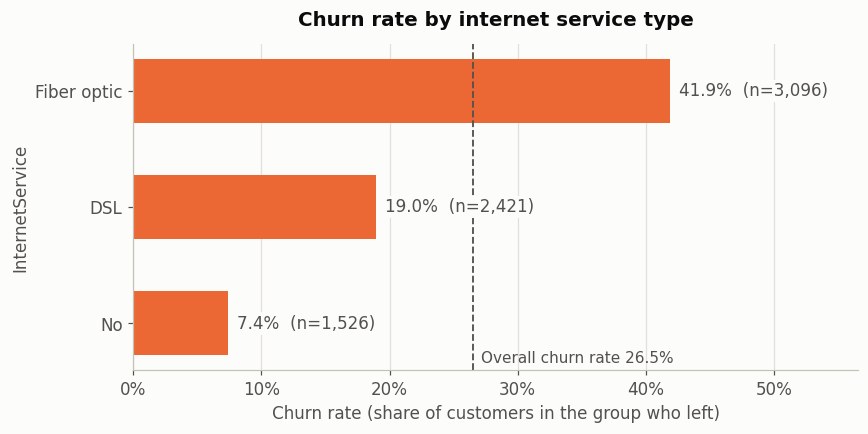

In [5]:
plot_churn_rate("InternetService", "Churn rate by internet service type", "03_churn_by_internet_service.png")

**Observation.** Fibre-optic customers churn at **41.9%**, more than double DSL (**19.0%**), while customers
without internet service churn at only **7.4%**. Fibre plans are the most expensive (see MonthlyCharges below),
so price and service type are likely intertwined. The 1,526 "No internet service" customers also explain the
"No internet service" level in the six add-on columns (OnlineSecurity … StreamingMovies).

### 4. Churn by PaymentMethod

,customers,churned,churn_rate
PaymentMethod,,,
Electronic check,"2,365","1,071",45.3%
Mailed check,"1,612",308,19.1%
Bank transfer (automatic),"1,544",258,16.7%
Credit card (automatic),"1,522",232,15.2%


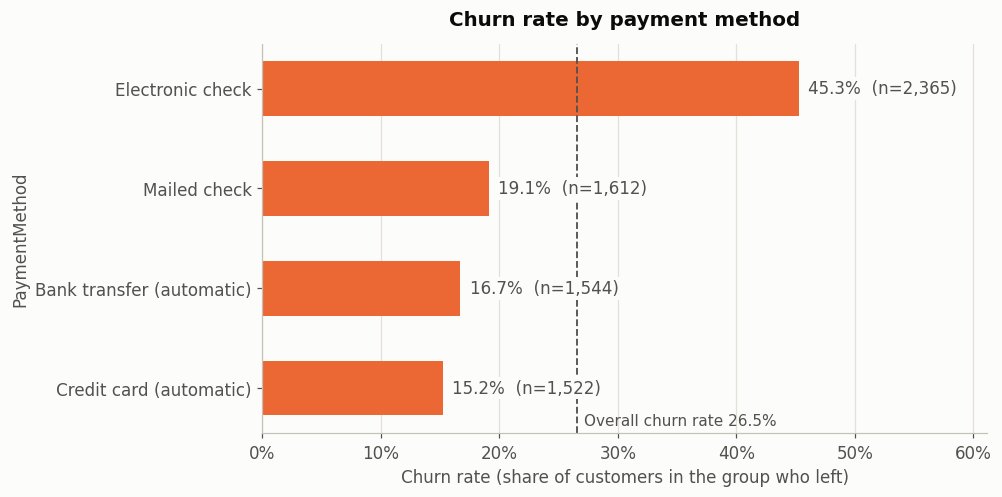

In [6]:
plot_churn_rate("PaymentMethod", "Churn rate by payment method", "04_churn_by_payment_method.png")

**Observation.** Electronic-check payers churn at **45.3%**, roughly 2.4–3× the other methods (mailed check 19.1%,
bank transfer 16.7%, credit card 15.2%). The two *automatic* methods have the lowest churn, which is consistent with
automatic payment reflecting a more settled, longer-term relationship.

## 5. Tenure distribution

In [7]:
def plot_distribution(column, bins, xlabel, title, filename):
    fig, (ax_all, ax_split) = plt.subplots(1, 2, figsize=(13, 4.6))

    ax_all.hist(df[column], bins=bins, color=NEUTRAL, edgecolor=SURFACE, linewidth=1)
    ax_all.set_title(f"{title}: all customers")
    ax_all.set_xlabel(xlabel)
    ax_all.set_ylabel("Number of customers")
    ax_all.grid(axis="x", visible=False)

    # Each group normalised to 100% so the two shapes are comparable despite the 2.8:1 imbalance.
    for value, label, color in (("No", "Stayed (No)", STAYED), ("Yes", "Churned (Yes)", CHURNED)):
        values = df.loc[df["Churn"] == value, column]
        ax_split.hist(values, bins=bins, weights=np.ones(len(values)) / len(values),
                      histtype="step", linewidth=2.2, color=color, label=label)
    ax_split.set_title(f"{title}: by churn status")
    ax_split.set_xlabel(xlabel)
    ax_split.set_ylabel("Share of customers in group")
    ax_split.yaxis.set_major_formatter(PercentFormatter(1.0))
    ax_split.legend(title="Churn", loc="upper center")
    ax_split.grid(axis="x", visible=False)

    fig.tight_layout()
    fig.savefig(FIG_DIR / filename)
    plt.show()
    display(df.groupby("Churn")[column].describe().round(2))

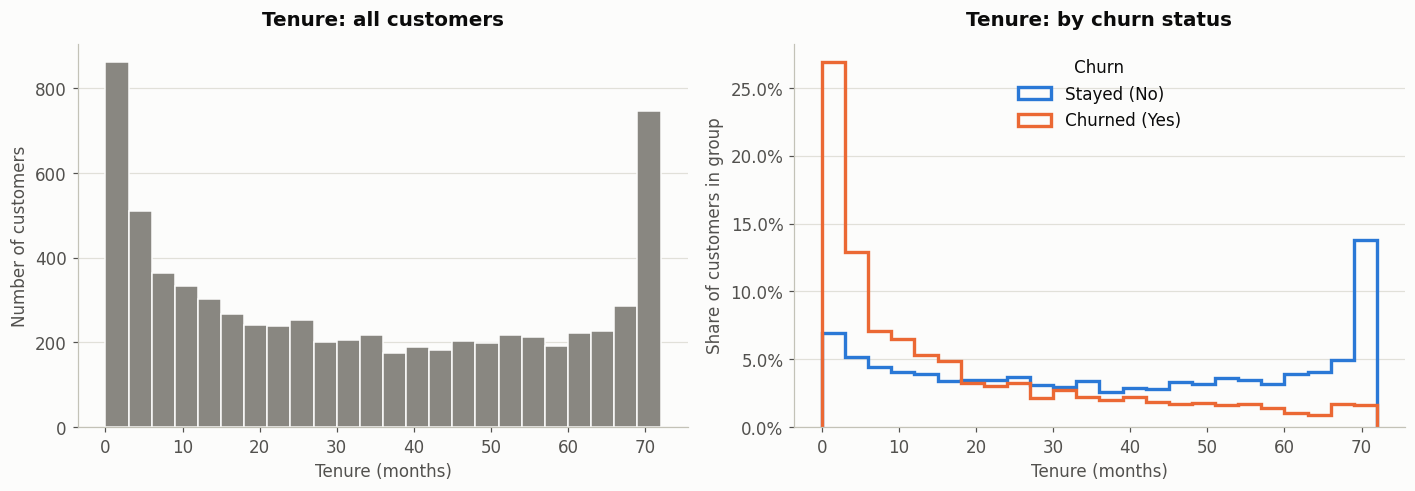

,count,mean,std,min,25%,50%,75%,max
Churn,,,,,,,,
No,5174.0,37.57,24.11,0.0,15.0,38.0,61.0,72.0
Yes,1869.0,17.98,19.53,1.0,2.0,10.0,29.0,72.0


In [8]:
plot_distribution("tenure", np.arange(0, 75, 3), "Tenure (months)", "Tenure", "05_tenure_distribution.png")

In [9]:
tenure_bands = pd.cut(df["tenure"], [-1, 6, 12, 24, 48, 72],
                      labels=["0–6", "7–12", "13–24", "25–48", "49–72"])
(df.groupby(tenure_bands, observed=True)["churned"].agg(customers="size", churn_rate="mean")
   .style.format({"churn_rate": "{:.1%}", "customers": "{:,}"}))

,customers,churn_rate
tenure,,
0–6,"1,481",52.9%
7–12,705,35.9%
13–24,"1,024",28.7%
25–48,"1,594",20.4%
49–72,"2,239",9.5%


**Observation.** Tenure is U-shaped overall: many very new customers (613 at 1 month) and a spike of long-standing
customers at the 72-month cap (362). The two groups look very different. Churners are concentrated in the first
months (median **10** months vs **38** for those who stayed), and churn falls steadily with tenure, from about
half of customers in the first six months to **9.5%** after four years. The 11 `tenure = 0` customers have not
been billed yet and none of them churned.

## 6. MonthlyCharges distribution

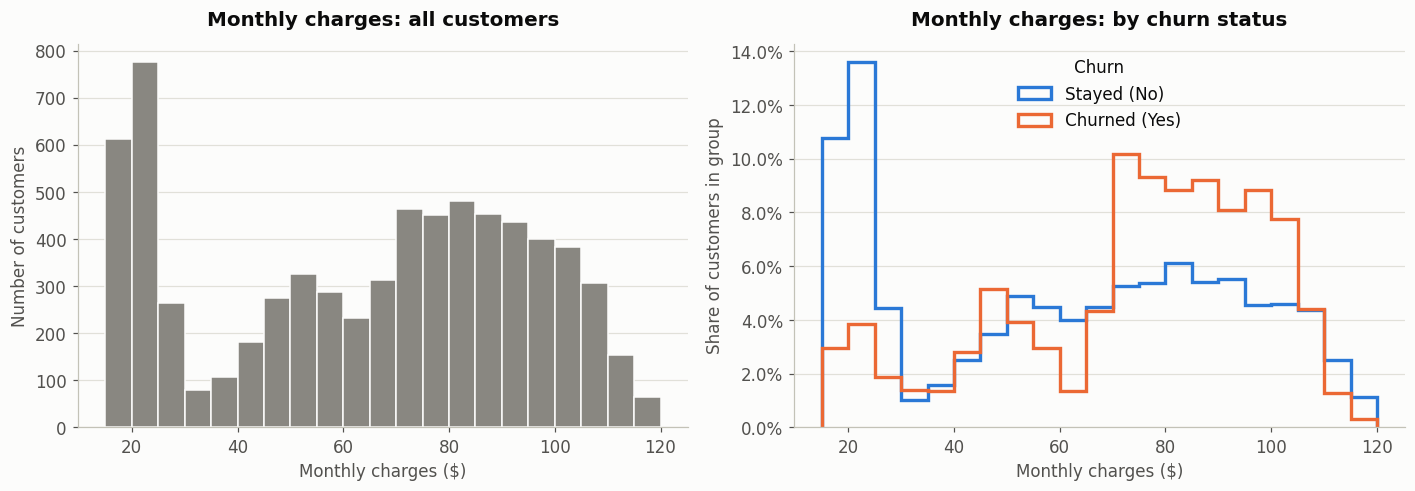

,count,mean,std,min,25%,50%,75%,max
Churn,,,,,,,,
No,5174.0,61.27,31.09,18.25,25.10,64.43,88.4,118.75
Yes,1869.0,74.44,24.67,18.85,56.15,79.65,94.2,118.35


In [10]:
plot_distribution("MonthlyCharges", np.arange(15, 125, 5), "Monthly charges ($)", "Monthly charges", "06_monthly_charges_distribution.png")

**Observation.** Monthly charges are bimodal: a tall peak around **$20–25** (1,389 customers pay under $25, mostly
phone-only plans with no internet) and a broad hump from about $70 to $105. Churners are shifted towards higher
charges (median **$79.65** vs **$64.43**), and the $20–25 peak is made up almost entirely of customers who stayed.
The relationship is not monotonic, though: the highest-priced customers are often long-tenure bundle customers,
so MonthlyCharges is best read together with tenure and contract.

## 7. Correlation heatmap (numerical features)

,tenure,MonthlyCharges,TotalCharges,Churn (Yes=1)
tenure,1.000,0.248,0.826,-0.352
MonthlyCharges,0.248,1.000,0.651,0.193
TotalCharges,0.826,0.651,1.000,-0.198
Churn (Yes=1),-0.352,0.193,-0.198,1.000


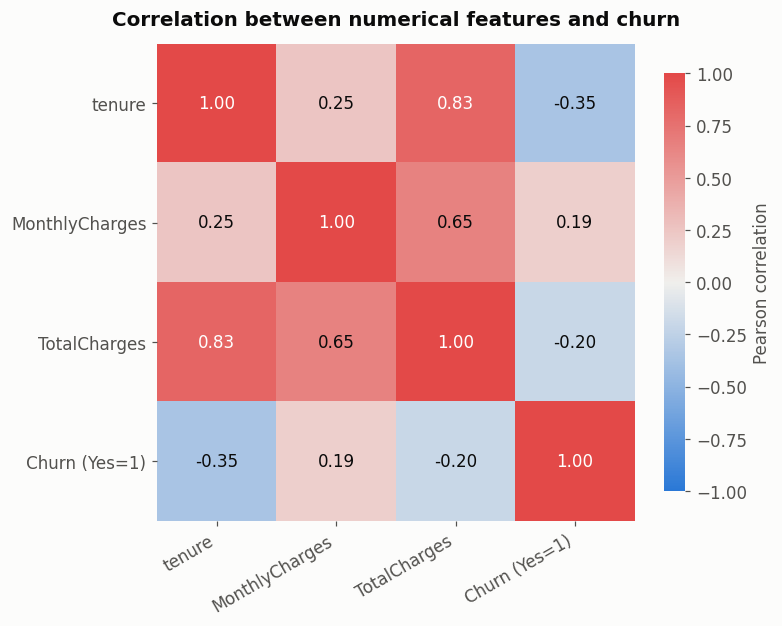

In [11]:
corr = df[NUMERICAL_FEATURES + ["churned"]].rename(columns={"churned": "Churn (Yes=1)"}).corr()
display(corr.round(3))

diverging = LinearSegmentedColormap.from_list("blue_gray_red", ["#2a78d6", "#f0efec", "#e34948"])
fig, ax = plt.subplots(figsize=(7, 5.8))
image = ax.imshow(corr, cmap=diverging, vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=30, ha="right")
ax.set_yticks(range(len(corr)), corr.columns)
ax.grid(False)
for spine in ax.spines.values():
    spine.set_visible(False)
for i in range(len(corr)):
    for j in range(len(corr)):
        value = corr.iat[i, j]
        ax.text(j, i, f"{value:.2f}", ha="center", va="center",
                color="white" if abs(value) > 0.7 else INK, fontsize=11)
colorbar = fig.colorbar(image, ax=ax, shrink=0.85)
colorbar.set_label("Pearson correlation")
colorbar.outline.set_visible(False)
ax.set_title("Correlation between numerical features and churn")
fig.savefig(FIG_DIR / "07_correlation_heatmap.png")
plt.show()

**Observation.** TotalCharges is strongly correlated with tenure (**0.83**) and moderately with MonthlyCharges
(**0.65**), as expected since TotalCharges ≈ tenure × MonthlyCharges. This redundancy (multicollinearity) can make
logistic-regression coefficients unstable, but it does not harm tree-based models. Against the target, tenure has the
strongest linear relationship (**−0.35**: longer tenure, less churn), followed by TotalCharges (−0.20) and
MonthlyCharges (+0.19). (Churn is included as a 0/1 column for reference; it is the target, not an input.)

## 8. Summary of observations

| Pattern | Evidence |
|---|---|
| Moderate class imbalance | 73.5% No / 26.5% Yes |
| Short commitments churn most | Month-to-month 42.7% vs two-year 2.8% |
| Fibre-optic customers churn most | 41.9% vs DSL 19.0%, no internet 7.4% |
| Electronic-check payers churn most | 45.3% vs 15–19% for other methods |
| New customers are the highest risk | Churner median tenure 10 months vs 38; ~53% churn in months 1–6 |
| Higher monthly charges, more churn | Churner median $79.65 vs $64.43 |
| TotalCharges is largely redundant | r = 0.83 with tenure, 0.65 with MonthlyCharges |

**Implications for modelling (later phases, not implemented here)**
- Use metrics that respect the imbalance (F1, recall, AUC, MCC) and keep the stratified split.
- The risk factors overlap (a new, month-to-month, fibre, electronic-check customer combines several), so models that
  capture interactions, such as tree ensembles, may outperform a purely linear model.
- Keep all 19 features for now. The TotalCharges redundancy mainly matters when interpreting linear-model coefficients.
- Scaling of tenure / MonthlyCharges / TotalCharges is already part of the preprocessing pipeline, which matters
  for distance- and gradient-based models (kNN, logistic regression).